In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from markov_model import load_inputs, run_both

p, S = load_inputs()     # same base-case inputs as every other notebook
DAYS = 365.25            # days per year (same convention as Step 2)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
# Drug acquisition cost per patient, using ODB unit prices (October 2026).
# CDA-AMC convention: unit price x units per day x 365.25.
# Mark-ups and dispensing fees are excluded.
cma = pd.DataFrame([
    {"regimen": "Apixaban 5 mg, generic",          "dosing": "1 tablet twice daily", "unit_price": 0.4084, "units_per_day": 2},
    {"regimen": "Edoxaban 60 mg, generic",         "dosing": "1 tablet once daily",  "unit_price": 0.7348, "units_per_day": 1},
    {"regimen": "Apixaban 5 mg, brand (Eliquis)",  "dosing": "1 tablet twice daily", "unit_price": 1.6336, "units_per_day": 2},
])
cma["daily_cost"] = cma["unit_price"] * cma["units_per_day"]
cma["annual_cost"] = cma["daily_cost"] * DAYS

# Warfarin's cost is not just the tablet: INR blood tests are part of using it,
# so we add the annual monitoring cost from the model inputs.
warfarin_annual = p["c_warfarin"] + p["c_inr"]
cma.loc[len(cma)] = {"regimen": "Warfarin 5 mg + INR monitoring", "dosing": "daily, with INR testing",
                     "unit_price": np.nan, "units_per_day": np.nan,
                     "daily_cost": warfarin_annual / DAYS, "annual_cost": warfarin_annual}

# Difference from generic apixaban (positive = more expensive)
cma["vs generic apixaban"] = cma["annual_cost"] - cma.loc[0, "annual_cost"]
cma.to_csv("../outputs/cma.csv", index=False)
print(cma.to_string(index=False, formatters={"unit_price": "{:.4f}".format}))

                       regimen                  dosing unit_price  units_per_day  daily_cost  annual_cost  vs generic apixaban
        Apixaban 5 mg, generic    1 tablet twice daily     0.4084           2.00        0.82       298.34                 0.00
       Edoxaban 60 mg, generic     1 tablet once daily     0.7348           1.00        0.73       268.39               -29.95
Apixaban 5 mg, brand (Eliquis)    1 tablet twice daily     1.6336           2.00        3.27     1,193.34               895.01
Warfarin 5 mg + INR monitoring daily, with INR testing        NaN            NaN        1.05       384.23                85.89


In [3]:
# Who would switch? Built up step by step from the Ontario population.
# The last three inputs are ASSUMPTIONS (no current Ontario data found),
# so they are labelled as such in the report and tested in Cell 7.
BIA = {
    "pop_65plus":     3_100_000,          # Ontario residents aged 65+, 2025 (Ministry of Finance)
    "af_prevalence":  0.059,              # AF prevalence in 65+ (Feinberg et al. 1995)
    "share_on_oac":   0.60,               # ASSUMPTION: share of AF patients on an anticoagulant
    "share_warfarin": 0.15,               # ASSUMPTION: share of those still on warfarin
    "uptake":         [0.25, 0.50, 0.75], # ASSUMPTION: share switched by years 1, 2, 3
}
n_warfarin = BIA["pop_65plus"] * BIA["af_prevalence"] * BIA["share_on_oac"] * BIA["share_warfarin"]
print(f"Ontarians 65+ still on warfarin: {n_warfarin:,.0f}")

Ontarians 65+ still on warfarin: 16,461


In [4]:
# 1) DRUG PLAN view (CDA-AMC reference case for budget impact):
#    only the tablets. Apixaban replaces warfarin tablets.
#    INR tests are paid by OHIP labs, not the drug plan, so they're excluded here.
drug_diff = p["c_apixaban"] - p["c_warfarin"]
print(f"Drug plan: apixaban costs ${drug_diff:,.2f} more per patient-year")

# 2) HEALTH SYSTEM view: everything the Markov model counts
#    (drugs, INR, strokes, bleeds, long-term care), year by year, undiscounted
#    (budgets are in cash terms). The model already stores per-year costs
#    in "yearly_cost_undisc".
a, w = run_both(p, S)
health_diff = [float(a["yearly_cost_undisc"][i] - w["yearly_cost_undisc"][i]) for i in range(3)]
for i, d in enumerate(health_diff, start=1):
    print(f"Health system, year {i}: ${d:,.0f} per patient")

Drug plan: apixaban costs $243.73 more per patient-year
Health system, year 1: $-389 per patient
Health system, year 2: $-445 per patient
Health system, year 3: $-485 per patient


In [5]:
rows = []
for yr in range(3):
    switched = n_warfarin * BIA["uptake"][yr]          # patients on apixaban that year
    rows.append({"year": yr + 1,
                 "patients switched": switched,
                 "drug plan ($)": switched * drug_diff,
                 "health system ($)": switched * health_diff[yr]})
bia = pd.DataFrame(rows)

# Add a total row
bia.loc[len(bia)] = {"year": "Total", "patients switched": np.nan,
                     "drug plan ($)": bia["drug plan ($)"].sum(),
                     "health system ($)": bia["health system ($)"].sum()}
bia.to_csv("../outputs/bia.csv", index=False)
pd.set_option("display.float_format", "{:,.0f}".format)
print(bia.to_string(index=False))

 year  patients switched  drug plan ($)  health system ($)
    1              4,115      1,002,994         -1,599,026
    2              8,230      2,005,988         -3,659,910
    3             12,346      3,008,983         -5,993,196
Total                NaN      6,017,965        -11,252,132


In [6]:
# The share still on warfarin is the input we know least about,
# so we vary it between 5% and 30%.
for share in (0.05, 0.15, 0.30):
    n = BIA["pop_65plus"] * BIA["af_prevalence"] * BIA["share_on_oac"] * share
    total = sum(n * u * drug_diff for u in BIA["uptake"])
    print(f"Warfarin share {share:.0%}: {n:>7,.0f} patients -> 3-year drug-plan impact ${total / 1e6:,.2f}M")

Warfarin share 5%:   5,487 patients -> 3-year drug-plan impact $2.01M
Warfarin share 15%:  16,461 patients -> 3-year drug-plan impact $6.02M
Warfarin share 30%:  32,922 patients -> 3-year drug-plan impact $12.04M


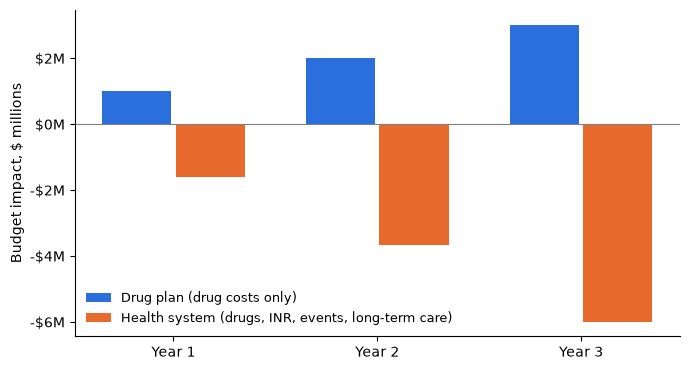

In [7]:
yrs = bia.iloc[:3]                     # drop the Total row
x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x - 0.18, yrs["drug plan ($)"] / 1e6, 0.34, color="#2a6fdb", label="Drug plan (drug costs only)")
ax.bar(x + 0.18, yrs["health system ($)"] / 1e6, 0.34, color="#e8692c",
       label="Health system (drugs, INR, events, long-term care)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(["Year 1", "Year 2", "Year 3"])
ax.set_ylabel("Budget impact, $ millions")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"-${abs(v):,.0f}M" if v < 0 else f"${v:,.0f}M"))
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../outputs/fig_bia.png", dpi=200)
plt.show()

In [8]:
## Interpretation
- The drug plan pays about **$6.0M more over 3 years**, because apixaban tablets cost more than warfarin tablets.
- The wider health system **saves about $11.3M**, from fewer INR tests, fewer strokes and ICH, and less long-term care.
- The two budgets are held by different payers (drug plan vs hospitals, labs and long-term care). That split is the policy point the BIA brings out.
- The 3-year drug-plan cost ranges from $2.0M to $12.0M depending on how many patients are still on warfarin, which is the least certain input.

SyntaxError: invalid decimal literal (1650669634.py, line 2)